# Simple Grid World: Prediction with TD(0) and Linear Approximation

Policy evaluation's job is to predict the value-function for the policy (i.e., all states visited by the policy).

## Installation and Setup

In [187]:
# uncomment if needed
# %pip install gym-classics2

# if the code produces an error, then try to install the package's latest version from github:
# %pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [188]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [189]:
import gymnasium as gym
import gym_classics2

Helper functions

In [190]:
from matplotlib import pyplot as plt

def v_hat_grid(x, y, w, state_features):
    return np.dot(w, state_features((x, y), env))

def show_value_function(w, state_features, title="Value Function"):
    x = np.linspace(0, env.dims[0]-1, 100)
    y = np.linspace(0, env.dims[1]-1, 100)
    X, Y = np.meshgrid(x, y)
    Z = np.array([v_hat_grid(x, y, w, state_features) for x, y in zip(np.ravel(X), np.ravel(Y))]).reshape(X.shape)

    plt.contourf(X, Y, Z, cmap='Reds')
    plt.title(title)
    plt.colorbar()
    plt.contour(X, Y, Z, colors='black') # Contour lines
    plt.show()

## Define the L-Maze

Create a non-tabular L-Maze. `tabular=False` means the states will be represented by `(x,y)` tuples and not integer IDs.



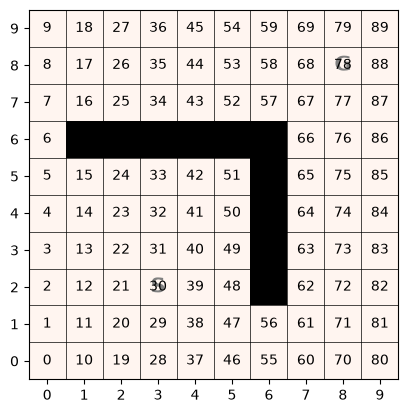

In [191]:
gym_env = gym.make('LMaze-v0', goal_reward = 99, step_reward = -1, tabular=False)
env = gym_env.unwrapped
env.reset(seed=SEED)

env.image()

In [192]:
print(env.states())

[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 7), (1, 8), (1, 9), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 7), (2, 8), (2, 9), (3, 0), (3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 7), (3, 8), (3, 9), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 7), (4, 8), (4, 9), (5, 0), (5, 1), (5, 2), (5, 3), (5, 4), (5, 5), (5, 7), (5, 8), (5, 9), (6, 0), (6, 1), (6, 7), (6, 8), (6, 9), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7), (7, 8), (7, 9), (8, 0), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]


## Define a Policy To Evaluate

I manually define the optimal policy that leads to the goal. I will use TD(0) to predict the value function for this policy.

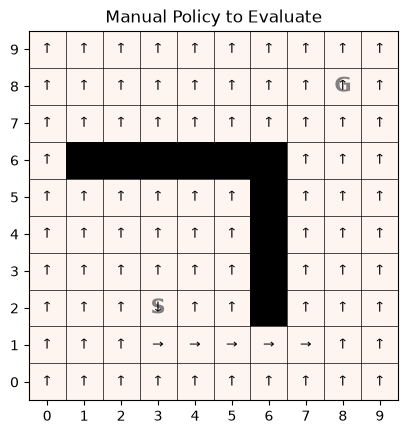

In [193]:
pol = np.full(len(env.states()), env.action2id('up'))
pol[[30]] = env.action2id('down')
pol[[29,38,47,56,61]] = env.action2id('right')
pol

env.image(policy = pol, title='Manual Policy to Evaluate')

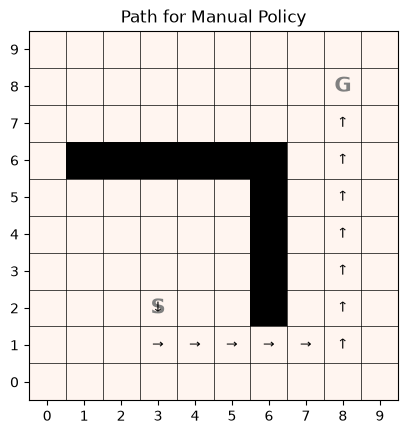

In [194]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

path = sample_episode(env, policy=pol, max_len=100, rng=rng)
env.image(policy=pol, episode=path, title='Path for Manual Policy')

## Prediction with Linear State Features

In [195]:
from gym_classics2.algorithms.linear_approximation import semi_gradient_TD0, v_hat

In [196]:
def linear_state_features(s, env):
    return np.concatenate([np.array([1]), np.array(s)])

In [197]:
w = semi_gradient_TD0(env, linear_state_features, pol, n=100, alpha=0.001, gamma=1, max_episode_length=1000)

Semi-Gradient TD(0): 100%|██████████| 100/100 [00:00<00:00, 3279.36it/s]


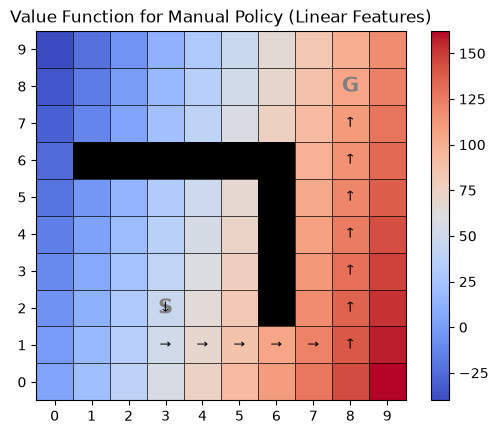

In [198]:
V = np.array([v_hat(s, w, env, linear_state_features) for s in env.states()])
env.image(V, episode=path, title = "Value Function for Manual Policy (Linear Features)")

Value function values along the states visited by the policy.

In [199]:
np.array([v_hat(s, w, env, linear_state_features) for (s,a,r,sp) in path])

array([ 47.09,  52.01,  69.58,  87.15, 104.72, 122.29, 139.86, 134.94,
       130.01, 125.09, 120.16, 115.24, 110.31])

**Issues:** Linear features are not able to express a value function along the states visited by the policy! They should be increasing and end up around 100 at the goal state.

## Prediction with Fourier Basis Function Features

We use up to order-10 Fourier features.

In [232]:
from gym_classics2.algorithms.linear_approximation import transformation_fourier_basis

transform = transformation_fourier_basis([0, 0], [9, 9], order=10)

def fourier_state_features(state, env):
    return transform(state)

In [ ]:
w = semi_gradient_TD0(env, fourier_state_features, pol, n=5000, alpha=0.0001, gamma=1, max_episode_length=1000)

Semi-Gradient TD(0):  10%|▉         | 492/5000 [00:00<00:03, 1185.29it/s]

Semi-Gradient TD(0): 100%|██████████| 5000/5000 [00:03<00:00, 1625.03it/s]


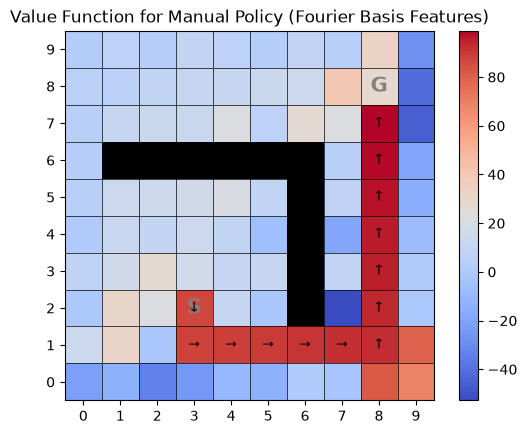

In [236]:
V = np.array([v_hat(s, w, env, fourier_state_features) for s in env.states()])
env.image(V, episode = path, title = "Value Function for Manual Policy (Fourier Basis Features)")

In [237]:
np.array([v_hat(s, w, env, fourier_state_features) for (s,a,r,sp) in path])

array([87.09, 87.95, 88.87, 89.88, 90.9 , 91.91, 92.95, 93.96, 94.98,
       95.99, 97.  , 98.  , 99.  ])

This value function along the states visited by the policy are very consistent with the policy.

Note that TD(0) only uses examples from the evaluated policy. All other values are the result of generalization of linear approximation with the global Fourier features. This leads to very large values off the policy path. This will be fixed when we use control, that estimates more values using exploration.

We can visualize the global struture of the estimated value function.

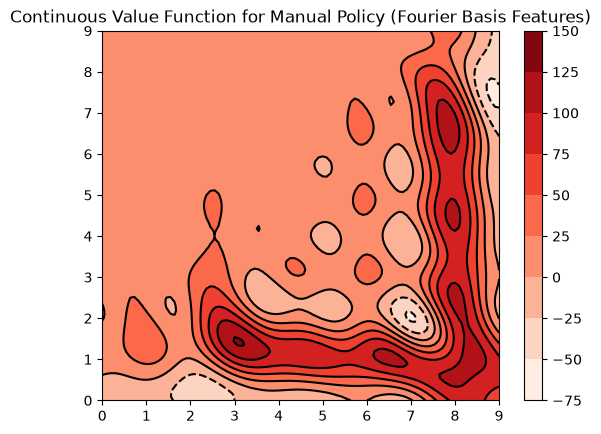

In [238]:
show_value_function(w, fourier_state_features, title="Continuous Value Function for Manual Policy (Fourier Basis Features)")


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)